# TP bandit à N bras

Les classes sont dans `bandit.py`, `players.py` et `simulation.py`. Les figures sont enregistrées dans `figures/`.

In [2]:
import inspect
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Code

from bandit import Bandit, Ban10
from players import GreedyPlayer, OptimistGreedyPlayer, UCBGreedyPlayer
from simulation import simulate

SEED = 42
random.seed(SEED)
os.makedirs("figures", exist_ok=True)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#888888",
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.8,
    "lines.linewidth": 1.6,
    "font.size": 10,
})

def show(obj):
    return Code(inspect.getsource(obj), language="python")

def normal_pdf(x, mu, sigma=1):
    return np.exp(-((x - mu) ** 2) / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))

ModuleNotFoundError: No module named 'matplotlib'

## Exercice 1 — Le bandit manchot

Classes `Bandit` et `Ban10` :

In [ ]:
import bandit
show(bandit)

import random


class Bandit:
    def __init__(self):
        self.avg = random.gauss(0, 1)

    def play(self):
        return random.gauss(self.avg, 1)


class Ban10:
    def __init__(self):
        self.bandits = [Bandit() for _ in range(10)]
        avgs = [b.avg for b in self.bandits]
        self.best_action = avgs.index(max(avgs))

    def play(self, action):
        return self.bandits[action].play()

### 1.3 — Distribution des gains d'un bandit

On joue 1000 fois le même bandit et on trace l'histogramme des gains, avec la densité théorique N(avg, 1) par-dessus.

avg du bandit = -0.144
moyenne observée = -0.161
variance observée = 1.040


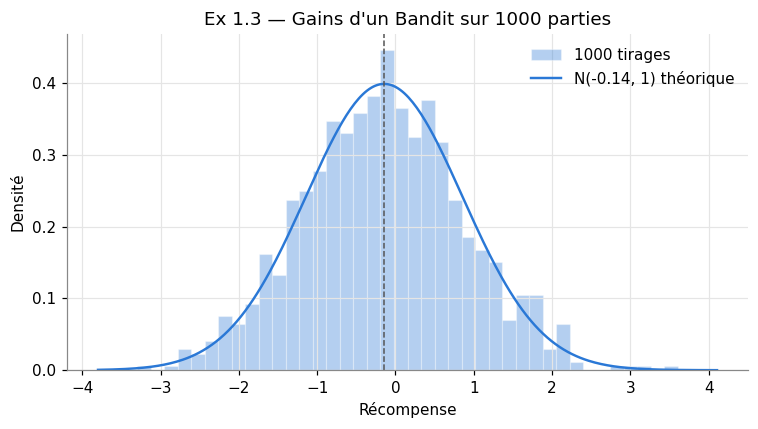

In [ ]:
bandit = Bandit()
values = [bandit.play() for _ in range(1000)]
print(f"avg du bandit = {bandit.avg:.3f}")
print(f"moyenne observée = {np.mean(values):.3f}")
print(f"variance observée = {np.var(values):.3f}")

x = np.linspace(min(values) - 0.5, max(values) + 0.5, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(values, bins=40, density=True, color=COLORS[0], alpha=0.35,
        edgecolor="white", linewidth=0.8, label="1000 tirages")
ax.plot(x, normal_pdf(x, bandit.avg), color=COLORS[0],
        label=f"N({bandit.avg:.2f}, 1) théorique")
ax.axvline(bandit.avg, color="#555555", linestyle="--", linewidth=1)
ax.set_title("Ex 1.3 — Gains d'un Bandit sur 1000 parties")
ax.set_xlabel("Récompense")
ax.set_ylabel("Densité")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/ex1_3_un_bandit.png")
plt.show()

### 1.4 — Trois bandits

Même chose avec 3 bandits : on doit voir 3 pics centrés sur 3 espérances différentes.

Bandit 0 : avg = 0.889, moyenne observée = 0.875
Bandit 1 : avg = -2.653, moyenne observée = -2.619
Bandit 2 : avg = -0.761, moyenne observée = -0.784


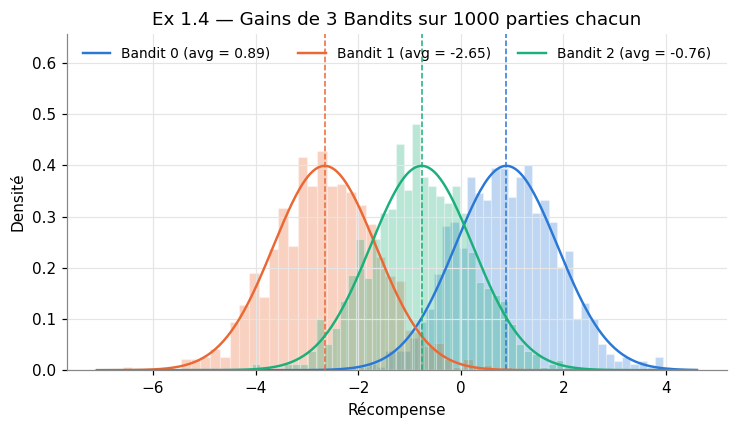

In [ ]:
bandits = [Bandit() for _ in range(3)]
fig, ax = plt.subplots(figsize=(7, 4))
all_values = []
for i, b in enumerate(bandits):
    vals = [b.play() for _ in range(1000)]
    all_values += vals
    print(f"Bandit {i} : avg = {b.avg:.3f}, moyenne observée = {np.mean(vals):.3f}")
    ax.hist(vals, bins=40, density=True, color=COLORS[i], alpha=0.3,
            edgecolor="white", linewidth=0.8)

x = np.linspace(min(all_values) - 0.5, max(all_values) + 0.5, 300)
for i, b in enumerate(bandits):
    ax.plot(x, normal_pdf(x, b.avg), color=COLORS[i],
            label=f"Bandit {i} (avg = {b.avg:.2f})")
    ax.axvline(b.avg, color=COLORS[i], linestyle="--", linewidth=1)

ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
ax.set_title("Ex 1.4 — Gains de 3 Bandits sur 1000 parties chacun")
ax.set_xlabel("Récompense")
ax.set_ylabel("Densité")
ax.legend(frameon=False, ncol=3, loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig("figures/ex1_4_trois_bandits.png")
plt.show()

## Exercice 3 — Algorithme ε-greedy

### 3.1 – 3.2 — Constructeur

`n` et `eps` sont stockés, et les tableaux Q (`action_values`) et N (`eval_count`) sont initialisés à 0.

In [ ]:
show(GreedyPlayer.__init__)

def __init__(self, n, eps):
        self.n = n
        self.eps = eps
        self.action_values = [0.0] * n  # Q
        self.eval_count = [0] * n       # N

In [ ]:
player = GreedyPlayer(10, 0.1)
print("n =", player.n, "| eps =", player.eps)
print("action_values =", player.action_values)
print("eval_count    =", player.eval_count)

n = 10 | eps = 0.1
action_values = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
eval_count    = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### 3.3, 3.4 et 3.7 — `get_action`

On tire un nombre entre 0 et 1 : s'il est inférieur à ε, `explore` vaut `True` et on joue au hasard, sinon on joue l'action greedy.

In [ ]:
show(GreedyPlayer.get_action)

def get_action(self):
        explore = random.random() < self.eps
        if explore:
            return self._random_action()
        return self._greedy_action()

### 3.5 — `_greedy_action`

Renvoie l'action de plus grande valeur estimée, au hasard parmi les ex æquo.

In [ ]:
show(GreedyPlayer._greedy_action)

def _greedy_action(self):
        best = max(self.action_values)
        best_actions = [a for a in range(self.n) if self.action_values[a] == best]
        return random.choice(best_actions)

In [ ]:
player = GreedyPlayer(10, 0.1)
player.action_values = [0, 1.5, 0.2, 1.5, -1, 0, 0, 1.5, 0, 0]
print("Q =", player.action_values)
print("10 appels à _greedy_action :", [player._greedy_action() for _ in range(10)])

Q = [0, 1.5, 0.2, 1.5, -1, 0, 0, 1.5, 0, 0]
10 appels à _greedy_action : [1, 7, 7, 3, 7, 3, 3, 1, 7, 7]


### 3.6 — `_random_action`

In [ ]:
show(GreedyPlayer._random_action)

def _random_action(self):
        return random.randrange(self.n)

In [ ]:
print("20 appels à _random_action :", [player._random_action() for _ in range(20)])

20 appels à _random_action : [6, 3, 7, 6, 5, 9, 9, 1, 6, 2, 4, 7, 3, 1, 4, 9, 8, 6, 4, 3]


### 3.7 — Vérification de la proportion d'exploration

Avec ε = 0.1 et Q comme ci-dessus, environ 90 % des actions doivent être 1, 3 ou 7, et le reste réparti sur les 10 bras.

In [ ]:
actions = [player.get_action() for _ in range(10_000)]
counts = np.bincount(actions, minlength=10)
for a, c in enumerate(counts):
    print(f"action {a} : {c / len(actions):6.2%}")

action 0 :  0.95%
action 1 : 31.20%
action 2 :  1.09%
action 3 : 30.97%
action 4 :  0.90%
action 5 :  1.17%
action 6 :  1.08%
action 7 : 30.79%
action 8 :  0.93%
action 9 :  0.92%


### 3.8 — `reward`

Met à jour N puis Q pour l'action jouée, avec la moyenne incrémentale :
Q(a) ← Q(a) + (R − Q(a)) / N(a)

In [ ]:
show(GreedyPlayer.reward)

def reward(self, action, value):
        self.eval_count[action] += 1
        q = self.action_values[action]
        self.action_values[action] = q + (value - q) / self.eval_count[action]

In [ ]:
player = GreedyPlayer(10, 0.1)
for r in [1.0, 2.0, 3.0]:
    player.reward(4, r)
    q, n = player.action_values[4], player.eval_count[4]
    print(f"reward(4, {r}) -> Q[4] = {q:.3f}, N[4] = {n}")
print("moyenne attendue :", np.mean([1.0, 2.0, 3.0]))

reward(4, 1.0) -> Q[4] = 1.000, N[4] = 1
reward(4, 2.0) -> Q[4] = 1.500, N[4] = 2
reward(4, 3.0) -> Q[4] = 2.000, N[4] = 3
moyenne attendue : 2.0


### 3.9 – 3.11 — Boucle de jeu complète

On crée un `Ban10` et un `GreedyPlayer(10, eps=0.1)`. Une itération enchaîne :

1. `get_action()` : le joueur choisit un levier ;
2. `ban.play(action)` : le `Ban10` renvoie la récompense ;
3. `reward(action, value)` : le joueur met à jour Q et N.

On répète 1000 fois (3.10). Pour le test (3.11), on garde à chaque itération la récompense et si le choix était optimal (`action == ban.best_action`). On n'affiche que les 10 premières et les 5 dernières lignes : les 1000 valeurs sont toutes conservées.


In [ ]:
def play_one_run(player, ban, steps=1000, verbose=True):
    rewards, optimal = [], []
    for t in range(1, steps + 1):
        action = player.get_action()          # le joueur choisit un levier
        value = ban.play(action)              # le Ban10 renvoie la récompense
        player.reward(action, value)          # le joueur met à jour Q et N
        is_optimal = action == ban.best_action
        rewards.append(value)
        optimal.append(is_optimal)
        if verbose and (t <= 10 or t > steps - 5):
            print(f"t = {t:4d} | action = {action} | récompense = {value:+.3f}"
                  f" | optimal = {is_optimal}")
        elif verbose and t == 11:
            print("   ...")
    return np.array(rewards), np.array(optimal)


In [ ]:
random.seed(SEED)
ban = Ban10()
player = GreedyPlayer(10, eps=0.1)
print("meilleur bras :", ban.best_action,
      "| vraies moyennes :", [round(b.avg, 2) for b in ban.bandits])
rewards, optimal = play_one_run(player, ban)
print(f"\nrécompense moyenne = {rewards.mean():.3f} | choix optimaux = {optimal.mean():.1%}")
print("N =", player.eval_count)
print("Q =", [round(q, 2) for q in player.action_values])


meilleur bras : 3 | vraies moyennes : [-0.14, -0.17, -0.11, 0.7, -0.13, -1.5, 0.33, -0.27, -0.22, 0.12]
t =    1 | action = 8 | récompense = -1.246 | optimal = False
t =    2 | action = 9 | récompense = -0.652 | optimal = False
t =    3 | action = 7 | récompense = -1.809 | optimal = False
t =    4 | action = 2 | récompense = -1.080 | optimal = False
t =    5 | action = 3 | récompense = +0.581 | optimal = True
t =    6 | action = 3 | récompense = +1.388 | optimal = True
t =    7 | action = 1 | récompense = -0.754 | optimal = False
t =    8 | action = 3 | récompense = +1.413 | optimal = True
t =    9 | action = 3 | récompense = +1.663 | optimal = True
t =   10 | action = 3 | récompense = +0.538 | optimal = True
   ...
t =  996 | action = 3 | récompense = +0.960 | optimal = True
t =  997 | action = 3 | récompense = +0.644 | optimal = True
t =  998 | action = 3 | récompense = +0.393 | optimal = True
t =  999 | action = 3 | récompense = -0.273 | optimal = True
t = 1000 | action = 3 | récomp

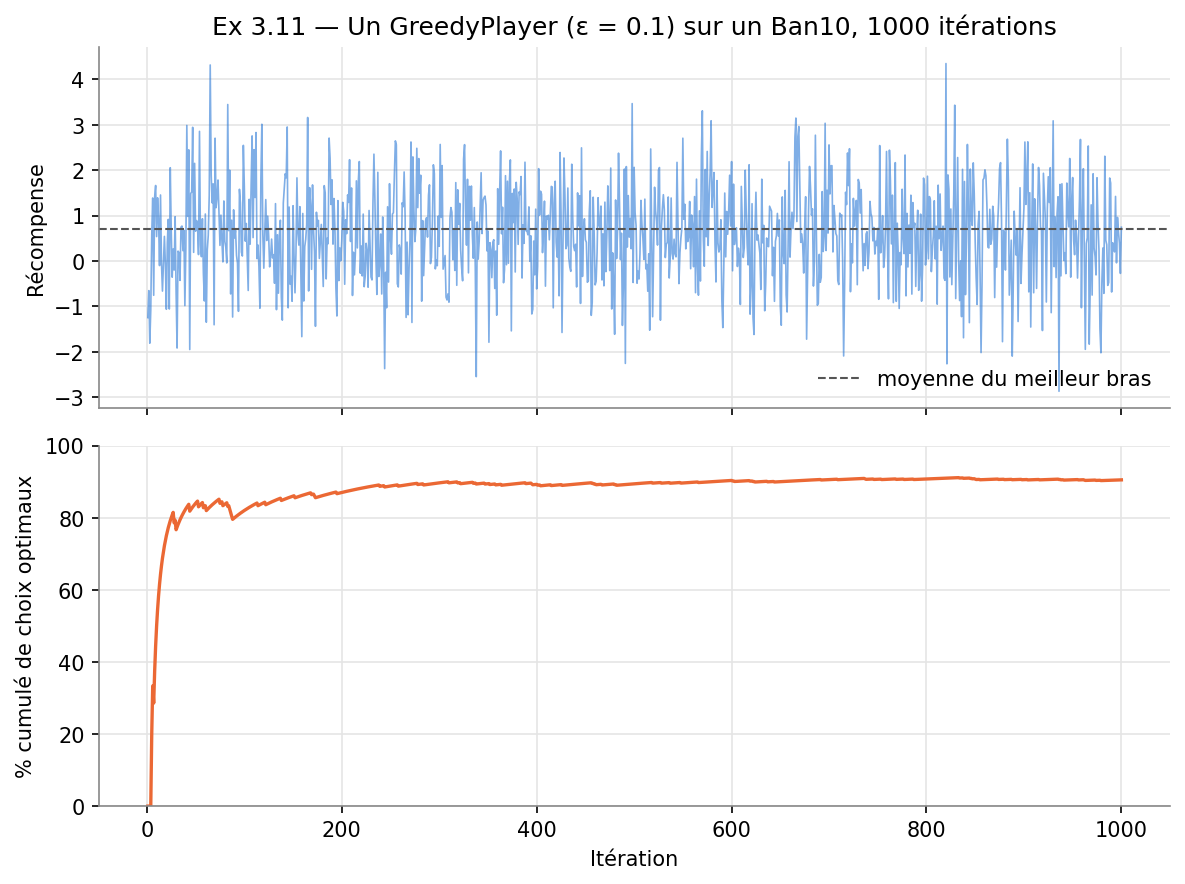

In [ ]:
steps = np.arange(1, len(rewards) + 1)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.plot(steps, rewards, color=COLORS[0], alpha=0.6, linewidth=0.8)
ax1.axhline(max(b.avg for b in ban.bandits), color="#555555", linestyle="--",
            linewidth=1, label="moyenne du meilleur bras")
ax1.set_ylabel("Récompense")
ax1.set_title("Ex 3.11 — Un GreedyPlayer (ε = 0.1) sur un Ban10, 1000 itérations")
ax1.legend(frameon=False, loc="lower right")
ax2.plot(steps, 100 * np.cumsum(optimal) / steps, color=COLORS[1])
ax2.set_ylabel("% cumulé de choix optimaux")
ax2.set_xlabel("Itération")
ax2.set_ylim(0, 100)
fig.tight_layout()
fig.savefig("figures/ex3_11_une_partie.png")
plt.show()


## Exercice 5 — Initialisation optimiste

### 5.3 — Optimiste (Q₀ = 5, ε = 0) contre ε-greedy (ε = 0.1)

`OptimistGreedyPlayer` (5.1, 5.2) :

In [ ]:
show(OptimistGreedyPlayer)

class OptimistGreedyPlayer(GreedyPlayer):
    def __init__(self, n, eps=0, q0=5):
        super().__init__(n, eps)
        self.action_values = [float(q0)] * n

2000 problèmes `Ban10`, 1000 étapes. Les deux joueurs jouent sur **les mêmes** objets `Ban10`, toutes les instances avancent étape par étape (fonction `simulate`).

In [ ]:
show(simulate)

def simulate(players, runs=2000, steps=1000):
    """Fait jouer chaque type de joueur sur les mêmes `runs` Ban10, étape par étape.

    players : dict nom -> fonction qui crée un joueur
    Renvoie un dict nom -> (récompense moyenne, % de choix optimal) par étape.
    """
    bans = [Ban10() for _ in range(runs)]
    results = {}
    for name, make_player in players.items():
        instances = [make_player() for _ in range(runs)]
        rewards = np.zeros(steps)
        optimal = np.zeros(steps)
        for t in range(steps):
            for ban, player in zip(bans, instances):
                action = player.get_action()
                value = ban.play(action)
                player.reward(action, value)
                rewards[t] += value
                optimal[t] += action == ban.best_action
        results[name] = (rewards / runs, 100 * optimal / runs)
    return results

In [ ]:
random.seed(SEED)
results_5 = simulate({
    "Optimiste, Q₀ = 5, ε = 0": lambda: OptimistGreedyPlayer(10, eps=0, q0=5),
    "ε-greedy, Q₀ = 0, ε = 0.1": lambda: GreedyPlayer(10, eps=0.1),
})

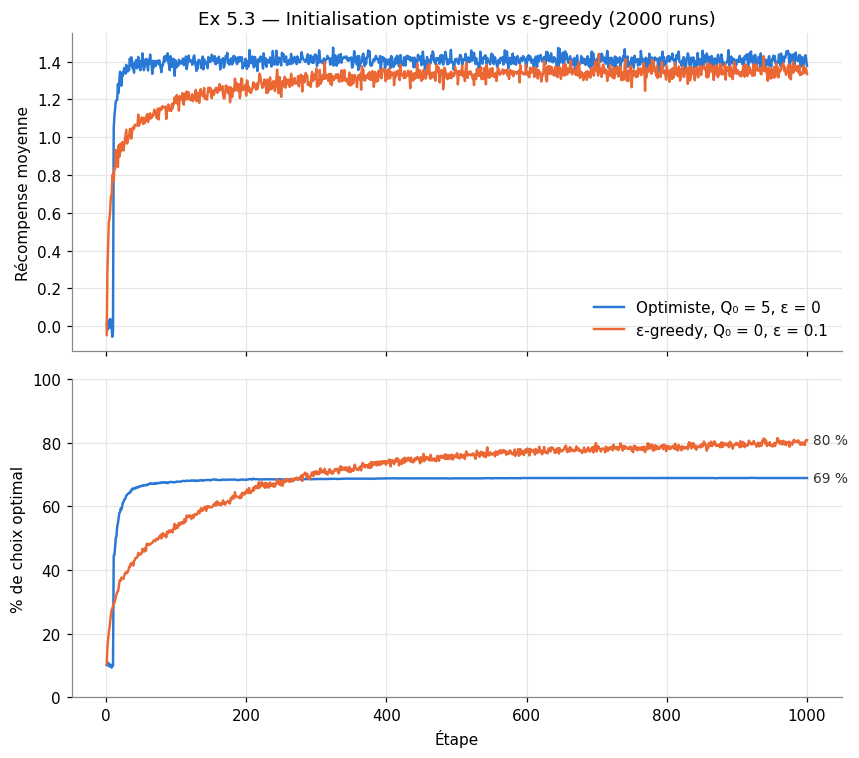

In [ ]:
def plot_comparison(results, title, path):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
    for i, (name, (rewards, optimal)) in enumerate(results.items()):
        steps = np.arange(1, len(rewards) + 1)
        ax1.plot(steps, rewards, color=COLORS[i], label=name)
        ax2.plot(steps, optimal, color=COLORS[i], label=name)
        ax2.annotate(f"{optimal[-50:].mean():.0f} %", (steps[-1], optimal[-1]),
                     xytext=(4, 0), textcoords="offset points",
                     va="center", fontsize=9, color="#333333")
    ax1.set_ylabel("Récompense moyenne")
    ax1.set_title(title)
    ax1.legend(frameon=False, loc="lower right")
    ax2.set_ylabel("% de choix optimal")
    ax2.set_xlabel("Étape")
    ax2.set_ylim(0, 100)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

plot_comparison(results_5, "Ex 5.3 — Initialisation optimiste vs ε-greedy (2000 runs)",
                "figures/ex5_3_optimiste_vs_greedy.png")

In [ ]:
for name, (rewards, optimal) in results_5.items():
    print(f"{name:27s} | récompense moy. = {rewards[-200:].mean():.3f}"
          f" | % optimal = {optimal[-200:].mean():.1f} %  (200 dernières étapes)")

Optimiste, Q₀ = 5, ε = 0    | récompense moy. = 1.408 | % optimal = 68.9 %  (200 dernières étapes)
ε-greedy, Q₀ = 0, ε = 0.1   | récompense moy. = 1.350 | % optimal = 79.4 %  (200 dernières étapes)


## Exercice 6 — Sélection Upper-Confidence-Bound

### 6.1 — `UCBGreedyPlayer`

Hérite de `GreedyPlayer`, prend en plus `c` (degré d'exploration). On compte `t`, le nombre d'appels à `reward`.
Par défaut ε = 0 : c'est le terme de confiance qui gère l'exploration.

In [ ]:
show(UCBGreedyPlayer.__init__)

def __init__(self, n, c=2, eps=0):
        super().__init__(n, eps)
        self.c = c
        self.t = 0

In [ ]:
show(UCBGreedyPlayer.reward)

def reward(self, action, value):
        self.t += 1
        super().reward(action, value)

### 6.2 — `_greedy_action` surchargée

Formule du cours :

$$A_t = \underset{a}{\operatorname{argmax}} \left[ Q_t(a) + c \sqrt{\frac{\ln t}{N_t(a)}} \right]$$

Si N(a) = 0, l'action est considérée comme maximale : on joue d'abord chaque bras une fois.

In [ ]:
show(UCBGreedyPlayer._greedy_action)

def _greedy_action(self):
        # une action jamais jouée est considérée comme maximale
        untried = [a for a in range(self.n) if self.eval_count[a] == 0]
        if untried:
            return random.choice(untried)

        log_t = math.log(self.t)
        scores = [
            self.action_values[a] + self.c * math.sqrt(log_t / self.eval_count[a])
            for a in range(self.n)
        ]
        best = max(scores)
        return random.choice([a for a in range(self.n) if scores[a] == best])

In [ ]:
random.seed(SEED)
ban = Ban10()
ucb = UCBGreedyPlayer(10, c=2)
print("meilleur bras :", ban.best_action)
for t in range(15):
    a = ucb.get_action()
    r = ban.play(a)
    ucb.reward(a, r)
    print(f"t = {ucb.t:2d} | action = {a} | récompense = {r:+.2f}"
          f" | optimal = {a == ban.best_action}")

meilleur bras : 3
t =  1 | action = 8 | récompense = -1.25 | optimal = False
t =  2 | action = 9 | récompense = -0.65 | optimal = False
t =  3 | action = 7 | récompense = -1.81 | optimal = False
t =  4 | action = 6 | récompense = -0.64 | optimal = False
t =  5 | action = 3 | récompense = +0.39 | optimal = True
t =  6 | action = 2 | récompense = +0.38 | optimal = False
t =  7 | action = 5 | récompense = +0.09 | optimal = False
t =  8 | action = 0 | récompense = +0.96 | optimal = False
t =  9 | action = 1 | récompense = +0.79 | optimal = False
t = 10 | action = 4 | récompense = -0.29 | optimal = False
t = 11 | action = 0 | récompense = +0.55 | optimal = False
t = 12 | action = 1 | récompense = +0.03 | optimal = False
t = 13 | action = 3 | récompense = -0.10 | optimal = True
t = 14 | action = 2 | récompense = +0.64 | optimal = False
t = 15 | action = 5 | récompense = -2.25 | optimal = False


In [ ]:
for _ in range(985):
    a = ucb.get_action()
    ucb.reward(a, ban.play(a))

print("Après 1000 coups :")
print("N =", ucb.eval_count)
print("Q =", [round(q, 2) for q in ucb.action_values])
print("vraies moyennes =", [round(b.avg, 2) for b in ban.bandits])

Après 1000 coups :
N = [25, 17, 30, 687, 22, 5, 118, 17, 35, 44]
Q = [-0.16, -0.45, -0.14, 0.69, -0.25, -1.57, 0.4, -0.41, -0.02, 0.08]
vraies moyennes = [-0.14, -0.17, -0.11, 0.7, -0.13, -1.5, 0.33, -0.27, -0.22, 0.12]


### 6.3 — UCB contre ε-greedy

`UCBGreedyPlayer` (c = 2) contre `GreedyPlayer` avec ε = 0,1, sur les mêmes 2000 `Ban10` et 1000 étapes (fonction `simulate`, tracé avec `plot_comparison`).


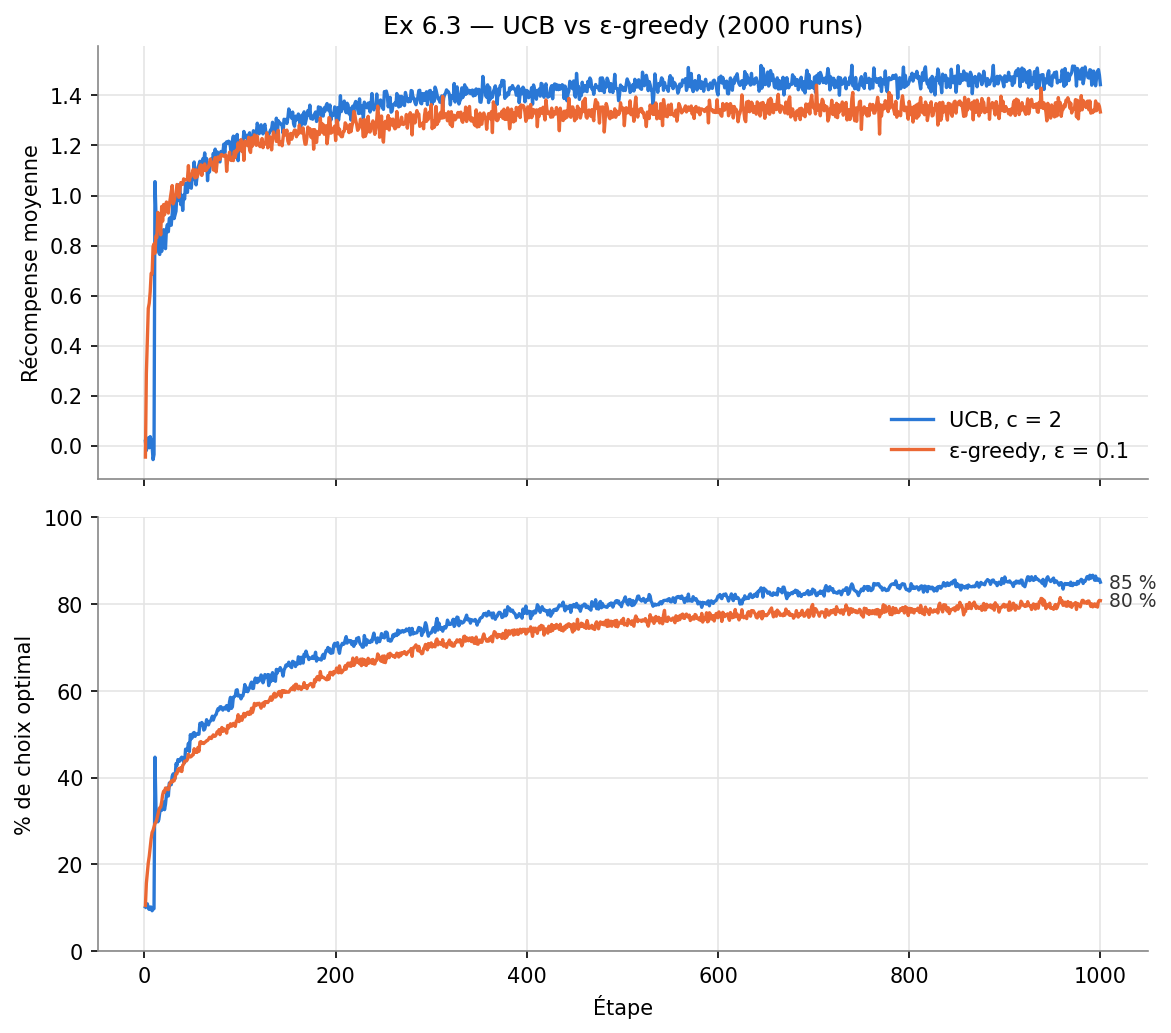

In [ ]:
random.seed(SEED)
results_6 = simulate({
    "UCB, c = 2": lambda: UCBGreedyPlayer(10, c=2),
    "ε-greedy, ε = 0.1": lambda: GreedyPlayer(10, eps=0.1),
})
plot_comparison(results_6, "Ex 6.3 — UCB vs ε-greedy (2000 runs)",
                "figures/ex6_3_ucb_vs_greedy.png")


In [ ]:
for t in [10, 11, 15, 30, 50, 100, 200, 500, 1000]:
    u, e = results_6["UCB, c = 2"], results_6["ε-greedy, ε = 0.1"]
    print(f"étape {t:4d} | récompense : UCB {u[0][t-1]:5.2f}, ε-greedy {e[0][t-1]:5.2f}"
          f" | % optimal : UCB {u[1][t-1]:5.1f}, ε-greedy {e[1][t-1]:5.1f}")
print()
for name, (rewards_, optimal_) in results_6.items():
    print(f"{name:18s} | récompense moy. = {rewards_[-200:].mean():.3f}"
          f" | % optimal = {optimal_[-200:].mean():.1f} %  (200 dernières étapes)")


étape   10 | récompense : UCB -0.04, ε-greedy  0.81 | % optimal : UCB   9.8, ε-greedy  28.6
étape   11 | récompense : UCB  1.06, ε-greedy  0.77 | % optimal : UCB  44.7, ε-greedy  29.4
étape   15 | récompense : UCB  0.77, ε-greedy  0.87 | % optimal : UCB  30.3, ε-greedy  32.4
étape   30 | récompense : UCB  0.97, ε-greedy  0.97 | % optimal : UCB  40.9, ε-greedy  39.5
étape   50 | récompense : UCB  1.07, ε-greedy  1.09 | % optimal : UCB  49.2, ε-greedy  45.2
étape  100 | récompense : UCB  1.20, ε-greedy  1.20 | % optimal : UCB  59.0, ε-greedy  54.0
étape  200 | récompense : UCB  1.33, ε-greedy  1.22 | % optimal : UCB  70.3, ε-greedy  64.4
étape  500 | récompense : UCB  1.43, ε-greedy  1.34 | % optimal : UCB  80.4, ε-greedy  75.5
étape 1000 | récompense : UCB  1.44, ε-greedy  1.33 | % optimal : UCB  85.0, ε-greedy  80.8

UCB, c = 2         | récompense moy. = 1.469 | % optimal = 84.8 %  (200 dernières étapes)
ε-greedy, ε = 0.1  | récompense moy. = 1.350 | % optimal = 79.4 %  (200 dernières

## Exercice 7 (Bonus) — Problèmes non-stationnaires

### 7.1 — `MovingBandit`

Hérite de `Bandit`. Sa moyenne suit un sinus : `avg(t) = centre + amplitude × sin(2π·t/période + phase)`.

- période aléatoire entre 100 et 500 coups ;
- min et max du sinus aléatoires (deux tirages gaussiens triés, le centre est leur milieu, l'amplitude leur demi-écart) ;
- phase aléatoire, pour que les bras ne soient pas synchronisés ;
- la moyenne change à chaque appel de `play`.


In [ ]:
from moving import MovingBandit, MovingBan10, simulate_moving
show(MovingBandit)


class MovingBandit(Bandit):
    """Bandit dont la moyenne `avg` bouge un peu à chaque appel de `play`.

    avg(t) = centre + amplitude * sin(2*pi*t/periode + phase)
    - periode : aléatoire entre 100 et 500 coups
    - min et max du sinus : aléatoires (deux tirages gaussiens triés)
    - phase : aléatoire, pour que les bandits ne soient pas tous synchronisés
    """

    def __init__(self):
        super().__init__()                    # tire un premier avg (inutilisé ensuite)
        self.period = random.uniform(100, 500)
        a, b = random.gauss(0, 1), random.gauss(0, 1)
        self.low, self.high = min(a, b), max(a, b)
        self.phase = random.uniform(0, 2 * math.pi)
        self.t = 0
        self._update_avg()

    def _update_avg(self):
        center = (self.low + self.high) / 2
        amplitude = (self.high - self.low) / 2
        self.avg = center + amplitude * math.sin(2 * math.pi * self.t / self.period + self.phase)

    def play(self):
        self.t += 1                           # la moyenne change à chaque coup
        self._update_avg()
        return super().play()                 # gauss(self.avg, 1), avec la nouvelle moyenne

### 7.2 — `MovingBan10`

Hérite de `Ban10` avec 10 `MovingBandit`. Le meilleur bras change au cours du temps : `best_action` devient une propriété recalculée à chaque accès (dans `Ban10`, elle est calculée une seule fois).


In [ ]:
show(MovingBan10)


class MovingBan10(Ban10):
    """Ban10 composé de 10 MovingBandit."""

    def __init__(self):
        self.bandits = [MovingBandit() for _ in range(10)]

    @property
    def best_action(self):
        # Le meilleur bras change au cours du temps : on le recalcule à chaque accès
        # (dans Ban10 c'est un attribut fixe calculé une seule fois au constructeur).
        avgs = [b.avg for b in self.bandits]
        return avgs.index(max(avgs))

### Vérification de 7.1 et 7.2

On joue 1000 coups sur 3 `MovingBandit` et on trace leur moyenne : on doit voir 3 sinusoïdes de périodes différentes, bornées par `low` et `high`. On vérifie aussi que `best_action` change au cours du temps.


Bandit 0 : période = 210, low = -0.17, high = 0.27 | avg observée : min = -0.17, max = 0.27
Bandit 1 : période = 457, low = 0.54, high = 0.89 | avg observée : min = 0.54, max = 0.89
Bandit 2 : période = 111, low = 0.46, high = 1.16 | avg observée : min = 0.46, max = 1.16


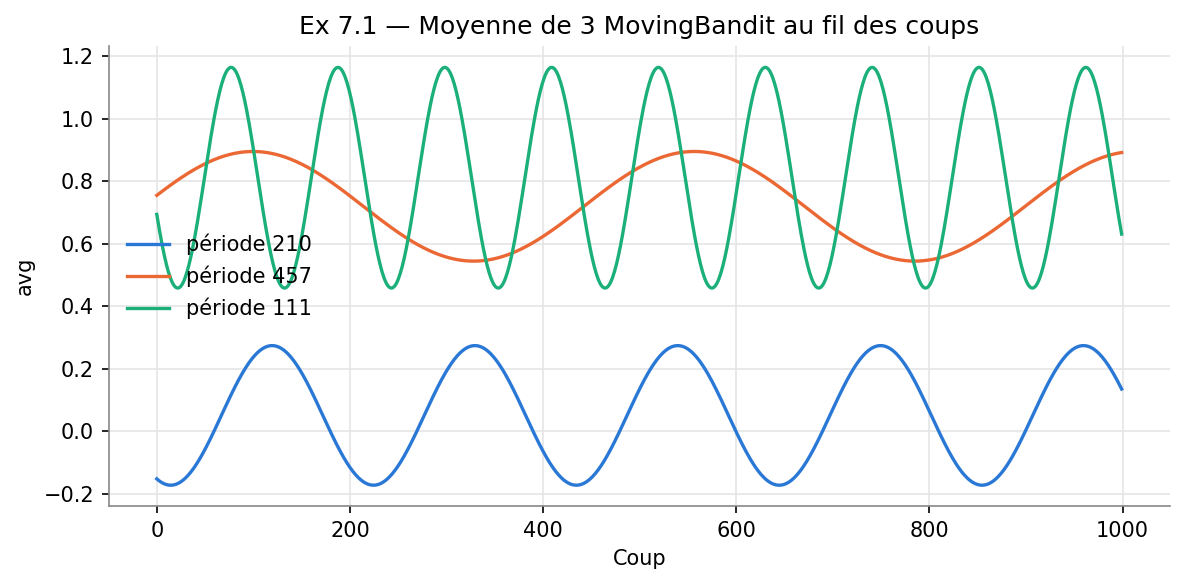

In [ ]:
random.seed(SEED)
moving_bandits = [MovingBandit() for _ in range(3)]
fig, ax = plt.subplots(figsize=(8, 4))
for i, b in enumerate(moving_bandits):
    avgs = []
    for _ in range(1000):
        b.play()
        avgs.append(b.avg)
    print(f"Bandit {i} : période = {b.period:.0f}, low = {b.low:.2f}, high = {b.high:.2f}"
          f" | avg observée : min = {min(avgs):.2f}, max = {max(avgs):.2f}")
    ax.plot(avgs, color=COLORS[i], label=f"période {b.period:.0f}")
ax.set_title("Ex 7.1 — Moyenne de 3 MovingBandit au fil des coups")
ax.set_xlabel("Coup")
ax.set_ylabel("avg")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("figures/ex7_1_moving_bandits.png")
plt.show()


In [ ]:
random.seed(SEED)
moving_ban = MovingBan10()
seen = []
for _ in range(1000):
    for b in moving_ban.bandits:
        b.play()
    if moving_ban.best_action not in seen:
        seen.append(moving_ban.best_action)
print("bras optimaux rencontrés pendant 1000 coups :", seen)


bras optimaux rencontrés pendant 1000 coups : [5, 9, 2, 4]


### `simulate_moving`

`simulate` fait jouer les types de joueurs l'un après l'autre sur les **mêmes** objets. Avec des bandits qui bougent à chaque `play`, le 2ᵉ joueur démarrerait 1000 coups plus loin dans le cycle du sinus : la comparaison serait faussée. `simulate_moving` garde une copie vierge des bandits et en donne une copie profonde (`copy.deepcopy`) à chaque type de joueur : tous partent du même état.


In [ ]:
show(simulate_moving)


def simulate_moving(players, runs=2000, steps=1000, make_ban=MovingBan10):
    """Comme `simulate`, mais valable pour des bandits qui évoluent.

    Problème avec `simulate` : tous les joueurs jouent l'un après l'autre sur les mêmes
    objets. Avec des bandits qui bougent à chaque `play`, le 2e joueur démarrerait
    1000 coups plus tard dans le cycle du sinus. On garde donc une copie vierge des
    `runs` bandits et on en donne une copie profonde (deepcopy) à chaque type de joueur :
    tous partent du même état initial, et la comparaison reste équitable.
    """
    pristine = [make_ban() for _ in range(runs)]
    results = {}
    for name, make_player in players.items():
        bans = copy.deepcopy(pristine)
        instances = [make_player() for _ in range(runs)]
        rewards = np.zeros(steps)
        optimal = np.zeros(steps)
        for t in range(steps):
            for ban, player in zip(bans, instances):
                action = player.get_action()
                value = ban.play(action)
                player.reward(action, value)
                rewards[t] += value
                optimal[t] += action == ban.best_action
        results[name] = (rewards / runs, 100 * optimal / runs)
    return results

In [ ]:
# Test d'équité : deux joueurs identiques doivent obtenir des résultats proches
random.seed(2)
check = simulate_moving({
    "A": lambda: GreedyPlayer(10, eps=0.1),
    "B": lambda: GreedyPlayer(10, eps=0.1),
}, runs=200, steps=300)
for name, (rewards_, optimal_) in check.items():
    print(f"joueur {name} : récompense moyenne = {rewards_.mean():.3f}")


joueur A : récompense moyenne = 0.772
joueur B : récompense moyenne = 0.778
